In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from utils_survey_analysis import *
import ipywidgets as widgets
from IPython.display import display
%matplotlib inline

In [36]:
    base_csv = "data/survey/data-base.csv"
    personnes_csv = "data/survey/data-personnes.csv"
    photos_csv = "data/survey/data-photos.csv"

In [37]:
df = import_and_merge_data_base(base_csv, personnes_csv, photos_csv)
df = df[df['job'] == 6]
df = df[df['postal_code'].between(69000, 70000, inclusive='neither')]

In [50]:
categories = ['gender', 'electric_bike', 'bike_use_frequency','type']

In [51]:
for cat in categories:
    print(f"\n--- Analyse globale par : {cat} ---")
    global_stats = df.groupby(cat)['note'].agg(
        Moyenne='mean',
        Écart_type='std',
        Nombre_évaluations='count'
    ).reset_index()
    print(global_stats)


--- Analyse globale par : gender ---
   gender   Moyenne  Écart_type  Nombre_évaluations
0       0  3.263529    1.245472                 850
1       1  3.374332    1.227394                1122
2       2  2.941176    1.347077                  34

--- Analyse globale par : electric_bike ---
   electric_bike   Moyenne  Écart_type  Nombre_évaluations
0          False  3.306574    1.257440                1445
1           True  3.354724    1.189545                 561

--- Analyse globale par : bike_use_frequency ---
   bike_use_frequency   Moyenne  Écart_type  Nombre_évaluations
0                   0  3.067227    1.246902                 119
1                   1  3.153846    1.214999                 221
2                   2  3.221289    1.278076                 357
3                   3  3.271493    1.264750                 442
4                   4  3.462514    1.199274                 867

--- Analyse globale par : type ---
   type   Moyenne  Écart_type  Nombre_évaluations
0     0  2.2

In [52]:
for cat in categories:
    print(f"\n--- Note moyenne par photo selon : {cat} (Aperçu) ---")
    photo_cat_pivot = df.pivot_table(
        index='id_photo',
        columns=cat,
        values='note',
        aggfunc='mean'
    )
    print(photo_cat_pivot.head(10))


--- Note moyenne par photo selon : gender (Aperçu) ---
gender       0         1    2
id_photo                     
1         4.62  4.636364  4.5
2         4.16  4.151515  3.5
3         3.06  3.196970  3.5
4         2.46  2.515152  1.5
5         3.98  4.060606  1.5
6         3.96  3.757576  3.5
7         2.14  2.409091  1.5
8         2.84  3.045455  2.5
9         3.80  4.045455  3.0
10        3.02  3.121212  3.0

--- Note moyenne par photo selon : electric_bike (Aperçu) ---
electric_bike     False     True 
id_photo                         
1              4.623529  4.636364
2              4.070588  4.333333
3              3.105882  3.242424
4              2.400000  2.666667
5              3.941176  4.090909
6              3.905882  3.666667
7              2.211765  2.454545
8              2.894118  3.090909
9              3.952941  3.848485
10             3.082353  3.060606

--- Note moyenne par photo selon : bike_use_frequency (Aperçu) ---
bike_use_frequency         0         1       

In [53]:
for cat in categories:
    clean_df = df.dropna(subset=['note', cat])
    groups = [group['note'].values for name, group in clean_df.groupby(cat)]

    if len(groups) == 2:
        stat, p_value = stats.ttest_ind(groups[0], groups[1], nan_policy='omit')
        print(f"Test t de Student pour {cat} -> p-value : {p_value:.5f}")
    elif len(groups) > 2:
        stat, p_value = stats.f_oneway(*groups)
        print(f"ANOVA (Test F) pour {cat} -> p-value : {p_value:.5f}")
    else:
        print(f"Pas assez de groupes pour {cat}")

ANOVA (Test F) pour gender -> p-value : 0.02858
Test t de Student pour electric_bike -> p-value : 0.43471
ANOVA (Test F) pour bike_use_frequency -> p-value : 0.00010
ANOVA (Test F) pour type -> p-value : 0.00000


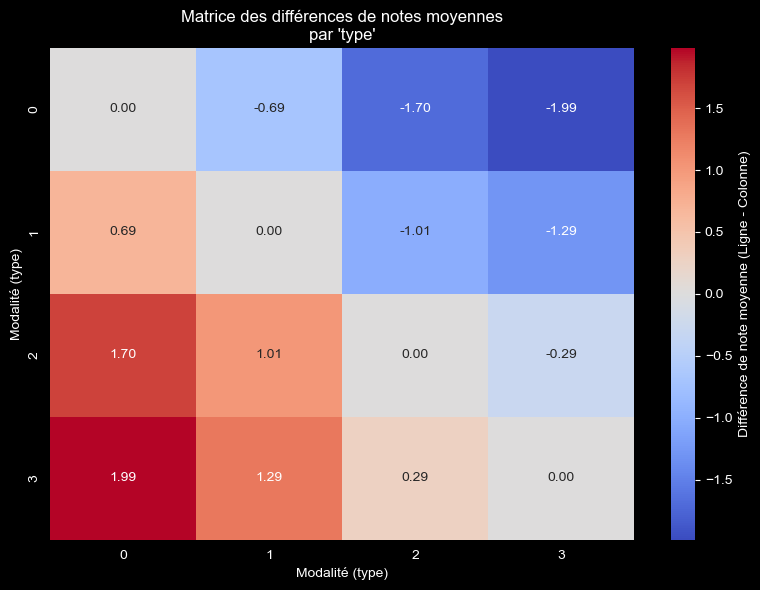

In [56]:
variable = 'type' # Vous pouvez changer par 'age', 'gender', etc.
id_photo_val = "all"
# 1. Calcul de la moyenne des notes pour chaque modalité
if id_photo_val == "all":
    df_filtered = df.copy()
else:
    df_filtered = df[df['id_photo'] == id_photo_val]
means = df_filtered.groupby(variable)['note'].mean()

# 2. Création de la matrice de différences (Moyenne_i - Moyenne_j)
diff_matrix = pd.DataFrame(
    np.subtract.outer(means.values, means.values),
    index=means.index,
    columns=means.index
)

# 3. Affichage de la Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    diff_matrix,
    annot=True,          # Affiche la valeur de la différence dans la case
    cmap='coolwarm',     # Palette divergente (bleu/rouge)
    center=0,            # Centre le blanc sur 0 (aucune différence)
    fmt=".2f",
    cbar_kws={'label': 'Différence de note moyenne (Ligne - Colonne)'}
)
plt.title(f"Matrice des différences de notes moyennes\npar '{variable}'")
plt.xlabel(f"Modalité ({variable})")
plt.ylabel(f"Modalité ({variable})")
plt.tight_layout()
plt.show()